Coverage Matrix (Facilities x Nodes):
 [[1 1 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 1 1 1]]


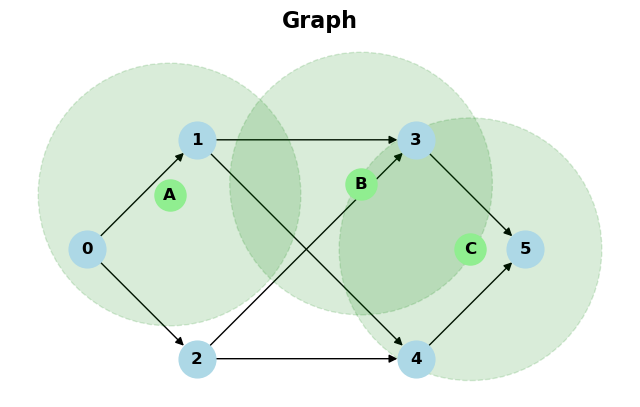

In [29]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

nodes = {0: (0, 0), 1: (1, 1), 2: (1, -1), 3: (3, 1), 4: (3, -1), 5: (4, 0)}
edges = [(0, 1), (0, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 5), (4, 5)]
facilities = {'A': (0.75, 0.5), 'B': (2.5, 0.6), 'C': (3.5, 0)}

r = 1.2  # Radius threshold


node_ids = list(nodes.keys())
node_coords = np.array(list(nodes.values()))
fac_ids = list(facilities.keys())
fac_coords = np.array(list(facilities.values()))
covered_nodes = {}
# Looping over potential facilities < looping over nodes 
dist_matrix = np.linalg.norm(fac_coords[:, None, :] - node_coords[None, :, :], axis=2)
coverage_matrix = dist_matrix <= r
print("Coverage Matrix (Facilities x Nodes):\n", coverage_matrix.astype(int))


G = nx.DiGraph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)
fig, ax = plt.subplots(figsize=(8, 5))
nx.draw(G, pos=nodes, with_labels=True, node_size=700, node_color='lightblue', arrowsize=12, ax=ax, font_weight='bold')
H = nx.Graph()
H.add_nodes_from(facilities)
nx.draw_networkx_nodes(H, pos=facilities, node_size=500, node_color='lightgreen', label='Facilities', ax=ax)
nx.draw_networkx_labels(H, pos=facilities, font_size=12, font_color='black', ax=ax, font_weight='bold')
for pos in facilities.values():
    circle = plt.Circle(pos, r, color='green', alpha=0.15, ec='green', linestyle='--')
    ax.add_patch(circle)

ax.set_aspect('equal')
plt.title("Graph", weight='bold', fontsize=16)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

In [33]:
fac_coords[:, None, :]
diff = fac_coords[:, None, :] - node_coords[None, :, :]
diff

array([[[ 0.75,  0.5 ],
        [-0.25, -0.5 ],
        [-0.25,  1.5 ],
        [-2.25, -0.5 ],
        [-2.25,  1.5 ],
        [-3.25,  0.5 ]],

       [[ 2.5 ,  0.6 ],
        [ 1.5 , -0.4 ],
        [ 1.5 ,  1.6 ],
        [-0.5 , -0.4 ],
        [-0.5 ,  1.6 ],
        [-1.5 ,  0.6 ]],

       [[ 3.5 ,  0.  ],
        [ 2.5 , -1.  ],
        [ 2.5 ,  1.  ],
        [ 0.5 , -1.  ],
        [ 0.5 ,  1.  ],
        [-0.5 ,  0.  ]]])

In [42]:
(np.linalg.norm(diff, axis=2)<=1).astype(int)

array([[1, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1]])